In [1]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive/VLSI CODE")
PROJECT_DRIVE = DRIVE_ROOT / "ForgeHLS"
DATASET_DRIVE = DRIVE_ROOT / "dataset" / "data_of_designs_forgehls.json"

print("Project exists:", PROJECT_DRIVE.exists(), PROJECT_DRIVE)
print("Dataset exists:", DATASET_DRIVE.exists(), DATASET_DRIVE)

if not PROJECT_DRIVE.exists():
    raise FileNotFoundError(f"ForgeHLS folder not found: {PROJECT_DRIVE}")

if not DATASET_DRIVE.exists():
    raise FileNotFoundError(
        f"Raw dataset not found: {DATASET_DRIVE}\n"
        "Check whether the dataset is inside MyDrive/VLSI CODE/dataset/"
    )

print("Dataset size GB:", round(DATASET_DRIVE.stat().st_size / 1024**3, 3))

Project exists: True /content/drive/MyDrive/VLSI CODE/ForgeHLS
Dataset exists: True /content/drive/MyDrive/VLSI CODE/dataset/data_of_designs_forgehls.json
Dataset size GB: 0.902


In [3]:
!rm -rf /content/ForgeHLS
!mkdir -p /content/ForgeHLS

In [4]:
!cp -r "/content/drive/MyDrive/VLSI CODE/ForgeHLS/hls_ml" \
       "/content/ForgeHLS/hls_ml"

!cp "/content/drive/MyDrive/VLSI CODE/ForgeHLS/requirements.txt" \
    "/content/ForgeHLS/requirements.txt"

!cp "/content/drive/MyDrive/VLSI CODE/ForgeHLS/requirements-colab.txt" \
    "/content/ForgeHLS/requirements-colab.txt"

In [5]:
%cd /content/ForgeHLS/hls_ml

/content/ForgeHLS/hls_ml


In [6]:
!pip install -q -r ../requirements.txt
!pip install -q -r ../requirements-colab.txt

In [7]:
import sys
import numpy
import pandas
import scipy
import sklearn
import torch
import pyarrow

print("Python:", sys.version)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("PyArrow:", pyarrow.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable. Deep ensemble will run very slowly on CPU.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.1.3
Pandas: 2.2.3
SciPy: 1.16.3
Scikit-learn: 1.6.1
PyTorch: 2.11.0+cpu
PyArrow: 23.0.1
CUDA available: False


In [8]:
import os
from pathlib import Path

DATASET_PATH = Path(
    "/content/drive/MyDrive/VLSI CODE/dataset/data_of_designs_forgehls.json"
)

if not DATASET_PATH.exists():
    raise FileNotFoundError(DATASET_PATH)

os.environ["FORGEHLS_DATA_PATH"] = str(DATASET_PATH)

print("FORGEHLS_DATA_PATH =", os.environ["FORGEHLS_DATA_PATH"])

FORGEHLS_DATA_PATH = /content/drive/MyDrive/VLSI CODE/dataset/data_of_designs_forgehls.json


In [9]:
from pathlib import Path

SCRIPTS = Path("/content/ForgeHLS/hls_ml/scripts")

required_scripts = [
    "config.py",
    "feature_extractor.py",
    "dataset_audit.py",
    "build_dataset.py",
    "make_splits.py",
    "train_baselines.py",
    "train_tuned.py",
    "train_uncertainty.py",
    "evaluate.py",
    "ablation_study.py",
    "make_figures.py",
]

for name in required_scripts:
    path = SCRIPTS / name
    print(name, "OK" if path.exists() else "MISSING")

if not all((SCRIPTS / name).exists() for name in required_scripts):
    raise FileNotFoundError("One or more required scripts are missing.")

feature_text = (SCRIPTS / "feature_extractor.py").read_text()
baseline_text = (SCRIPTS / "train_baselines.py").read_text()
uq_text = (SCRIPTS / "train_uncertainty.py").read_text()

print("Strict required-field validation:",
      "_required_float" in feature_text)

print("Log-MAE present:",
      "LogMAE" in baseline_text)

print("Stale Deep Ensemble reuse blocked:",
      "Refusing to reuse stale Deep Ensemble artifacts" in uq_text)

config.py OK
feature_extractor.py OK
dataset_audit.py OK
build_dataset.py OK
make_splits.py OK
train_baselines.py OK
train_tuned.py OK
train_uncertainty.py OK
evaluate.py OK
ablation_study.py OK
make_figures.py OK
Strict required-field validation: True
Log-MAE present: True
Stale Deep Ensemble reuse blocked: True


In [10]:
!python -m py_compile scripts/*.py
!python scripts/code_review_checker.py

Automated Code Quality & Syntax Revision
Auditing 16 Python script files in /content/ForgeHLS/hls_ml/scripts...

[PASSED] ablation_study.py             
[PASSED] build_dataset.py              
[PASSED] code_review_checker.py        
[PASSED] config.py                     
[PASSED] dataset_audit.py              
[PASSED] evaluate.py                   
[PASSED] feature_extractor.py          
[PASSED] kernel_group_audit.py         
[PASSED] make_figures.py               
[PASSED] make_splits.py                
[PASSED] pragma_audit.py               
[PASSED] source_normalization_audit.py 
[PASSED] test_feature_extractor.py     
[PASSED] train_baselines.py            
[PASSED] train_tuned.py                
[PASSED] train_uncertainty.py          

Summary: 0 Syntax Errors found across all codebase scripts!


In [11]:
!python scripts/test_feature_extractor.py

Testing Feature Extractor (Milestone 1 - Step 1.2 Verification)
Feature Set A count: 3
Feature Set B count: 28
Feature Set C count: 42
Target count:        5

[1] Reading sample records from dataset...
Loaded 500 sample records for testing.

[2] Extracting features and targets...
Verification SUCCESS! Processed 500 rows in 4.880s (102.5 rows/sec).

Sample row extraction:
  Targets: {'Worst-caseLatency': 15735.0, 'LUT': 10365.0, 'DSP': 44.0, 'FF': 2750.0, 'BRAM_18K': 0.0}
  Feature Set A: {'TargetClockPeriod': 10.0, 'code_length': 25961.0, 'pragma_number': 32.0}
  Sample Pragma Feats (Set B): {'pragma_pipeline_enable': 1.0, 'pragma_unroll_count': 16.0, 'pragma_max_unroll_factor': 4.0, 'pragma_array_partition_cyclic': 0.0}
  Sample Structural Feats (Set C): {'code_line_count': 915.0, 'code_function_count': 15.0, 'code_total_loop_count': 16.0, 'code_max_nesting_depth': 3.0}

Verification 100% PASSED!


In [12]:
!python scripts/dataset_audit.py

ForgeHLS Dataset Audit

[1] Loading dataset...
Total records: 184,717

[2] Dataset summary
--------------------------------------------------
Unique sources           : 11
Unique algorithms        : 471
Unique design IDs        : 1,242
Unique source+algorithm  : 491

[3] Special fields
--------------------------------------------------
is_pareto: {True: 3803, False: 180914}
is_kernel: {False: 184717}

[4] Strategy distribution
--------------------------------------------------
high-latency-low-resource           : 61,886
medium-latency-medium-resource      : 61,419
low-latency-high-resource           : 61,412

[5] Top 20 algorithms
--------------------------------------------------
aes                                                : 2,150
chebyshev_filter                                   : 1,658
ludcmp                                             : 1,240
bidirectional_shift_register                       : 1,158
instruction_pipeline                               : 1,157
gsm           

In [13]:
!python scripts/build_dataset.py

Building Tabular Dataset (Milestone 2 - Step 2.1)

[1] Loading raw dataset JSON...
Loaded 184,717 records in 9.52s

[2] Extracting features, targets, and metadata...
  Processed 50,000/184,717 designs (105.4s, 474 rows/s)...
  Processed 100,000/184,717 designs (250.3s, 399 rows/s)...
  Processed 150,000/184,717 designs (405.6s, 370 rows/s)...
  Processed 184,717/184,717 designs (428.0s, 432 rows/s)...

[3] Converting to DataFrames & validating integrity...
  Integrity confirmed: 184,717 rows, 0 NaNs across all 42 features & 5 targets.
  Identified 491 distinct logical kernel groups.

[4] Saving processed datasets to disk...
  Saved Parquet: /content/ForgeHLS/hls_ml/data/dataset_features.parquet (0.79 MB)
  Saved Parquet: /content/ForgeHLS/hls_ml/data/dataset_targets.parquet (1.39 MB)
  Saved Parquet: /content/ForgeHLS/hls_ml/data/dataset_metadata.parquet (0.03 MB)
  Saved NPZ:     /content/ForgeHLS/hls_ml/data/dataset_arrays.npz (1.99 MB)
  Saved schema reference: /content/ForgeHLS/hls

In [14]:
!python scripts/make_splits.py

Generating Leakage-Free Dataset Splits (Milestone 2 - Step 2.2)

[1] Loading dataset metadata...
Total designs: 184,717
Unique logical kernel groups: 491

[2] Generating E1: Random Row Split (80/20, seed=42)...
  Train designs: 147,773 (80.0%)
  Test designs:  36,944 (20.0%)
  [H1 Motivation Check] Groups present in BOTH train and test: 478/491 (97.4%)

[3] Generating E2 & E3: Repeated Kernel-Disjoint Splits...
  Seed 42: Train 145,661 (78.9%, 392 groups) | Test 39,056 (21.1%, 99 groups) | Overlap: 0 (PASSED)
  Seed 43: Train 148,673 (80.5%, 392 groups) | Test 36,044 (19.5%, 99 groups) | Overlap: 0 (PASSED)
  Seed 44: Train 144,678 (78.3%, 392 groups) | Test 40,039 (21.7%, 99 groups) | Overlap: 0 (PASSED)
  Seed 45: Train 150,275 (81.4%, 392 groups) | Test 34,442 (18.6%, 99 groups) | Overlap: 0 (PASSED)
  Seed 46: Train 150,372 (81.4%, 392 groups) | Test 34,345 (18.6%, 99 groups) | Overlap: 0 (PASSED)

[4] Saved compressed split masks to: /content/ForgeHLS/hls_ml/data/splits.npz (2.14 

In [15]:
import numpy as np
import json

data = np.load("data/dataset_arrays.npz", allow_pickle=False)
splits = np.load("data/splits.npz", allow_pickle=False)

print("X shape:", data["X_features"].shape)
print("Y shape:", data["y_targets"].shape)
print("Groups:", len(np.unique(data["group_ids"])))
print("Feature count:", len(data["feature_names"]))
print("Target count:", len(data["target_names"]))

assert data["X_features"].shape == (184717, 42)
assert data["y_targets"].shape == (184717, 5)
assert len(np.unique(data["group_ids"])) == 491

for seed in [42, 43, 44, 45, 46]:
    train_key = f"e3_grouped_seed_{seed}_train_idx"
    test_key = f"e3_grouped_seed_{seed}_test_idx"
    assert train_key in splits
    assert test_key in splits

print("Fresh dataset and split verification PASSED")

X shape: (184717, 42)
Y shape: (184717, 5)
Groups: 491
Feature count: 42
Target count: 5
Fresh dataset and split verification PASSED


In [16]:
from pathlib import Path

RESULTS = Path("results")

old_outputs = [
    "baseline_results_e1_vs_e2.csv",
    "baseline_results_e3_repeated.csv",
    "baseline_e2_predictions.npz",
    "baseline_summary.txt",
    "uncertainty_predictions.npz",
    "uncertainty_results.csv",
    "uncertainty_summary.txt",
    "calibration_metrics.csv",
    "risk_coverage_data.csv",
    "calibration_selective_summary.txt",
    "feature_ablation_results.csv",
    "ablation_summary.txt",
    "tuned_model_selection.csv",
    "tuned_results_e2.csv",
    "tuned_results_e3_by_seed.csv",
    "tuned_results_e3_summary.csv",
]

for name in old_outputs:
    path = RESULTS / name
    if path.exists():
        path.unlink()
        print("Deleted:", path)

print("Old experiment artifacts removed.")

Deleted: results/baseline_results_e1_vs_e2.csv
Deleted: results/baseline_results_e3_repeated.csv
Deleted: results/baseline_e2_predictions.npz
Deleted: results/baseline_summary.txt
Deleted: results/uncertainty_predictions.npz
Deleted: results/uncertainty_results.csv
Deleted: results/uncertainty_summary.txt
Deleted: results/calibration_metrics.csv
Deleted: results/risk_coverage_data.csv
Deleted: results/calibration_selective_summary.txt
Deleted: results/feature_ablation_results.csv
Deleted: results/ablation_summary.txt
Old experiment artifacts removed.


In [17]:
!python scripts/train_baselines.py

Training Baseline QoR Predictors (Milestone 3: E1, E2, E3)

[1] Loading dataset arrays and splits...
Loaded feature matrix: (184717, 42), targets matrix: (184717, 5)
Features: 42, Targets: ['Worst-caseLatency', 'LUT', 'DSP', 'FF', 'BRAM_18K']

[2] Running E1 (Random Row Split) vs E2 (Kernel-Disjoint Split)...

--- Model Family: Ridge ---
  [Worst-caseLatency ] E1(Random) R²=-0.131, MAE=4120248066.1 | E2(Disjoint) R²=0.629, MAE=343647351.0 | Shift Degradation: 0.08x
  [LUT               ] E1(Random) R²=-0.018, MAE=13592.1 | E2(Disjoint) R²=-2035.030, MAE=369578.6 | Shift Degradation: 27.19x
  [DSP               ] E1(Random) R²=-0.007, MAE=102.8 | E2(Disjoint) R²=-6606.976, MAE=8998.0 | Shift Degradation: 87.5x
  [FF                ] E1(Random) R²=-0.288, MAE=11174.6 | E2(Disjoint) R²=-226.813, MAE=128873.5 | Shift Degradation: 11.53x
  [BRAM_18K          ] E1(Random) R²=-0.001, MAE=13.9 | E2(Disjoint) R²=-4.422, MAE=2.6 | Shift Degradation: 0.19x

--- Model Family: RandomForest ---
  [W

In [18]:
import pandas as pd
import numpy as np
from pathlib import Path

baseline_csv = Path("results/baseline_results_e1_vs_e2.csv")
baseline_summary = Path("results/baseline_summary.txt")
baseline_predictions = Path("results/baseline_e2_predictions.npz")

assert baseline_csv.exists()
assert baseline_summary.exists()
assert baseline_predictions.exists()

baseline = pd.read_csv(baseline_csv)

required_columns = [
    "Model",
    "Target",
    "E1_R2",
    "E2_R2",
    "E1_LogMAE",
    "E2_LogMAE",
    "E1_LogR2",
    "E2_LogR2",
]

missing = [c for c in required_columns if c not in baseline.columns]
if missing:
    raise RuntimeError(f"Missing expected columns: {missing}")

numeric_columns = [
    "E1_R2",
    "E2_R2",
    "E1_MAE",
    "E2_MAE",
    "E1_LogMAE",
    "E2_LogMAE",
]

assert np.isfinite(baseline[numeric_columns].to_numpy()).all()

print("Baseline rows:", len(baseline))
print("Models:", baseline["Model"].unique())
print("Targets:", baseline["Target"].unique())
print("Fresh baseline verification PASSED")

display(baseline)

Baseline rows: 20
Models: ['Ridge' 'RandomForest' 'GradientBoosting' 'MLP']
Targets: ['Worst-caseLatency' 'LUT' 'DSP' 'FF' 'BRAM_18K']
Fresh baseline verification PASSED


,Model,Target,E1_R2,E1_MAE,E1_RMSE,E1_NMAE,E1_MedianAE,E1_LogMAE,E1_LogR2,E2_R2,E2_MAE,E2_RMSE,E2_NMAE,E2_MedianAE,E2_LogMAE,E2_LogR2,MAE_Degradation_Ratio,Fit_Time_s
0,Ridge,Worst-caseLatency,-0.1306,4.120248e+09,2.099947e+10,1.0419,3138.01,1.7282,0.7837,0.6288,3.436474e+08,2.095115e+09,0.5112,3642.00,2.3110,0.1498,0.08,1.77
1,Ridge,LUT,-0.0176,1.359211e+04,1.720620e+05,0.8545,857.63,0.8865,0.5621,-2035.0299,3.695787e+05,2.083805e+06,29.9421,903.49,1.1912,0.0725,27.19,1.50
2,Ridge,DSP,-0.0075,1.028300e+02,2.242000e+03,1.0387,2.17,1.0886,0.3844,-6606.9761,8.998040e+03,4.180837e+04,105.4116,2.40,1.4332,-0.3449,87.50,1.48
3,Ridge,FF,-0.2879,1.117464e+04,9.729765e+04,1.0373,373.02,1.2742,0.5062,-226.8125,1.288735e+05,8.752552e+05,11.9427,521.96,1.5326,0.2654,11.53,1.33
4,Ridge,BRAM_18K,-0.0007,1.389000e+01,2.351100e+02,0.9797,0.17,0.3203,0.3659,-4.4218,2.630000e+00,4.141000e+01,1.8369,0.24,0.4505,-0.9019,0.19,1.68
5,RandomForest,Worst-caseLatency,0.9647,6.553627e+08,3.711904e+09,0.1657,283.23,0.3396,0.9882,0.7314,3.452696e+08,1.782086e+09,0.5136,5040.14,1.7488,0.5529,0.53,64.46
6,RandomForest,LUT,0.2729,8.452560e+03,1.454408e+05,0.5314,223.89,0.3257,0.9186,-0.0427,1.360570e+04,4.715722e+04,1.1023,917.78,0.8453,0.5398,1.61,63.28
7,RandomForest,DSP,0.2255,6.095000e+01,1.965730e+03,0.6156,0.00,0.1747,0.9449,-0.3017,1.015500e+02,5.867900e+02,1.1896,0.34,0.8565,0.2473,1.67,50.55
8,RandomForest,FF,0.1604,6.953930e+03,7.855833e+04,0.6455,92.62,0.4265,0.9180,0.0103,1.090119e+04,5.768844e+04,1.0102,779.78,1.1405,0.5344,1.57,60.79
9,RandomForest,BRAM_18K,0.8513,3.400000e+00,9.064000e+01,0.2395,0.00,0.0377,0.9445,-0.0212,2.360000e+00,1.797000e+01,1.6493,0.00,0.4538,-1.1983,0.70,58.07


In [19]:
for model, group in baseline.groupby("Model"):
    log_degradation = (group["E2_LogMAE"] > group["E1_LogMAE"]).sum()
    r2_degradation = (group["E1_R2"] > group["E2_R2"]).sum()

    print(
        f"{model}: "
        f"log-MAE degradation {log_degradation}/{len(group)}, "
        f"R2 degradation {r2_degradation}/{len(group)}"
    )

overall_log_degradation = (
    baseline["E2_LogMAE"] > baseline["E1_LogMAE"]
).mean()

print("Overall log-MAE degradation fraction:",
      round(float(overall_log_degradation), 3))

GradientBoosting: log-MAE degradation 5/5, R2 degradation 4/5
MLP: log-MAE degradation 5/5, R2 degradation 5/5
RandomForest: log-MAE degradation 5/5, R2 degradation 5/5
Ridge: log-MAE degradation 5/5, R2 degradation 4/5
Overall log-MAE degradation fraction: 1.0


In [20]:
!python scripts/train_tuned.py

                Model            Target  Selection_LogMAE        R2          MAE    MedianAE   LogMAE  Positive_F1
    TunedRandomForest Worst-caseLatency          2.876790  0.721701 3.545224e+08 5256.771746 1.741411          NaN
TunedGradientBoosting Worst-caseLatency          2.478613  0.782832 3.003256e+08 4718.250874 1.595225          NaN
          TrainMedian Worst-caseLatency               NaN -0.038215 6.722216e+08 1919.000000 2.795764          NaN
    TunedRandomForest               LUT          0.884804 -0.045411 1.368655e+04  893.618850 0.856799          NaN
TunedGradientBoosting               LUT          0.874986  0.111572 1.078320e+04 1036.340179 0.781681          NaN
          TrainMedian               LUT               NaN -0.055200 1.177675e+04 1297.000000 1.482925          NaN
    TunedRandomForest               DSP          1.202219 -0.340502 1.016974e+02    0.349350 0.850420          NaN
TunedGradientBoosting               DSP          1.056876  0.021724 8.363725e+01

In [21]:
from pathlib import Path
import numpy as np
import pandas as pd

tuned_files = [
    "results/tuned_model_selection.csv",
    "results/tuned_results_e2.csv",
    "results/tuned_results_e3_by_seed.csv",
    "results/tuned_results_e3_summary.csv",
]

for name in tuned_files:
    path = Path(name)
    print(name, "OK" if path.exists() else "MISSING")
    assert path.exists()

tuned_e2 = pd.read_csv("results/tuned_results_e2.csv")
tuned_e3 = pd.read_csv("results/tuned_results_e3_summary.csv")
assert len(tuned_e2) > 0
assert len(tuned_e3) > 0
required_e2_metrics = ["R2", "MAE", "MedianAE", "LogMAE"]
missing_e2_metrics = [c for c in required_e2_metrics if c not in tuned_e2.columns]
assert not missing_e2_metrics, f"Missing required E2 metrics: {missing_e2_metrics}"
assert np.isfinite(tuned_e2[required_e2_metrics].to_numpy()).all()

# Selection_LogMAE and Positive_F1 are optional for baseline/median rows.
optional_e2_metrics = ["Selection_LogMAE", "Positive_F1"]
present_optional_e2 = [c for c in optional_e2_metrics if c in tuned_e2.columns]
if present_optional_e2:
    assert not np.isinf(tuned_e2[present_optional_e2].to_numpy()).any()

e3_numeric = tuned_e3.select_dtypes(include="number")
assert np.isfinite(e3_numeric.to_numpy()).all()

print("Tuned E2 rows:", len(tuned_e2))
print("Tuned E3 rows:", len(tuned_e3))
print("Fresh tuned-model verification PASSED")
display(tuned_e3)


results/tuned_model_selection.csv OK
results/tuned_results_e2.csv OK
results/tuned_results_e3_by_seed.csv OK
results/tuned_results_e3_summary.csv OK
Tuned E2 rows: 17
Tuned E3 rows: 10
Fresh tuned-model verification PASSED


,Model,Target,R2_mean,R2_std,MAE_mean,MAE_std,LogMAE_mean,LogMAE_std
0,TunedGradientBoosting,BRAM_18K,-8.655260,19.191542,1.947404e+01,2.346044e+01,0.420304,0.075082
1,TunedGradientBoosting,DSP,0.003031,0.010503,1.367306e+02,5.673778e+01,0.730275,0.109133
2,TunedGradientBoosting,FF,0.006534,0.007082,1.133375e+04,3.371301e+03,1.116343,0.049456
3,TunedGradientBoosting,LUT,0.022163,0.050492,1.501567e+04,6.215048e+03,0.842978,0.060187
4,TunedGradientBoosting,Worst-caseLatency,0.385615,0.238469,3.062238e+09,2.119944e+09,1.646877,0.231591
5,TunedRandomForest,BRAM_18K,-0.027293,0.015489,1.555585e+01,2.476407e+01,0.386892,0.087806
6,TunedRandomForest,DSP,-0.069788,0.151346,1.479053e+02,5.397647e+01,0.816158,0.083260
7,TunedRandomForest,FF,0.007359,0.008414,1.200709e+04,3.320561e+03,1.226773,0.114723
8,TunedRandomForest,LUT,-0.031300,0.039287,1.630483e+04,5.358568e+03,0.934753,0.082045
9,TunedRandomForest,Worst-caseLatency,-0.757309,2.348977,3.928100e+09,2.215924e+09,1.872623,0.248892


In [22]:
!python scripts/ablation_study.py

Running Feature Set Ablation Study (Milestone 6 - E8)

[1] Loading dataset arrays and schema...

[2] Training on E2 (Kernel-Disjoint) with Feature Sets A, B, and C...

--- Feature Configuration: Set_A_Basic (3 features) ---
  [Worst-caseLatency ] R²=-15.903 | MAE=2462534991.7 | Spearman rho=0.314 (2.8s)
  [LUT               ] R²=-0.207 | MAE=   19265.5 | Spearman rho=0.519 (1.9s)
  [DSP               ] R²=+0.050 | MAE=      93.0 | Spearman rho=0.536 (1.8s)
  [FF                ] R²=-0.450 | MAE=   21570.5 | Spearman rho=0.475 (1.9s)
  [BRAM_18K          ] R²=-1256.523 | MAE=      72.1 | Spearman rho=0.752 (1.5s)

--- Feature Configuration: Set_B_PragmaAware (28 features) ---
  [Worst-caseLatency ] R²=-2.344 | MAE=1472518312.1 | Spearman rho=0.637 (10.9s)
  [LUT               ] R²=-10.144 | MAE=   25305.4 | Spearman rho=0.481 (10.5s)
  [DSP               ] R²=-0.087 | MAE=     106.7 | Spearman rho=0.617 (8.2s)
  [FF                ] R²=-0.166 | MAE=   15633.4 | Spearman rho=0.551 (11.0s

In [23]:
import pandas as pd

ablation = pd.read_csv("results/feature_ablation_results.csv")

print("Ablation rows:", len(ablation))
print("Feature sets:", ablation["Feature_Set"].unique())
print("Targets:", ablation["Target"].unique())

display(ablation)

Ablation rows: 15
Feature sets: ['Set_A_Basic' 'Set_B_PragmaAware' 'Set_C_StructuralPragma']
Targets: ['Worst-caseLatency' 'LUT' 'DSP' 'FF' 'BRAM_18K']


,Feature_Set,Num_Features,Target,R2,MAE,MedianAE,LogMAE,Spearman_rho,Mean_Uncertainty
0,Set_A_Basic,3,Worst-caseLatency,-15.9034,2.462535e+09,6918.22,3.3676,0.3141,0.62
1,Set_A_Basic,3,LUT,-0.2070,1.926550e+04,2419.26,1.4385,0.5189,0.41
2,Set_A_Basic,3,DSP,0.0502,9.305000e+01,4.47,1.4771,0.5364,0.28
3,Set_A_Basic,3,FF,-0.4505,2.157054e+04,1465.37,1.9203,0.4746,0.48
4,Set_A_Basic,3,BRAM_18K,-1256.5231,7.208000e+01,0.00,0.6355,0.7515,0.11
5,Set_B_PragmaAware,28,Worst-caseLatency,-2.3445,1.472518e+09,5712.10,2.5847,0.6371,0.78
6,Set_B_PragmaAware,28,LUT,-10.1444,2.530545e+04,1763.72,1.1831,0.4809,0.50
7,Set_B_PragmaAware,28,DSP,-0.0868,1.066900e+02,5.00,1.4184,0.6170,0.45
8,Set_B_PragmaAware,28,FF,-0.1662,1.563335e+04,1335.97,1.5606,0.5506,0.61
9,Set_B_PragmaAware,28,BRAM_18K,0.1397,2.510000e+00,0.00,0.4113,0.7976,0.07


In [24]:
!python scripts/train_uncertainty.py

Training Uncertainty Quantification Models (Milestone 4: E4 & E5)
PyTorch device: cpu

[1] Loading dataset arrays and E2 (Kernel-Disjoint) split...
E2 Train: 145,661 designs | Test: 39,056 unseen designs

[2] Training Method A: Tree-Ensemble Disagreement UQ & Conformal Intervals...
  Fitting RF for Worst-caseLatency ... Done in 16.5s | Spearman rho = 0.884 | MAE Q1: 94482876.0 vs Q5: 4259242088.1 (45.08x)
  Fitting RF for LUT               ... Done in 16.5s | Spearman rho = 0.870 | MAE Q1: 217.2 vs Q5: 107970.5 (497.14x)
  Fitting RF for DSP               ... Done in 12.8s | Spearman rho = 0.902 | MAE Q1: 72.0 vs Q5: 6070.6 (84.36x)
  Fitting RF for FF                ... Done in 15.9s | Spearman rho = 0.847 | MAE Q1: 201.0 vs Q5: 254582.8 (1266.68x)
  Fitting RF for BRAM_18K          ... Done in 16.3s | Spearman rho = 0.989 | MAE Q1: 0.0 vs Q5: 67.9 (2585.30x)

[3] Training Method B: Deep Neural Ensemble (5 Models)...
  Training Ensemble Member 1/5 (Seed 100)... Done in 39.4s
  Trainin

In [25]:
from pathlib import Path
import numpy as np
import pandas as pd

uq_files = [
    "results/uncertainty_predictions.npz",
    "results/uncertainty_results.csv",
    "results/uncertainty_summary.txt",
]

for name in uq_files:
    path = Path(name)
    print(name, "OK" if path.exists() else "MISSING")
    assert path.exists()

uq = pd.read_csv("results/uncertainty_results.csv")
pred = np.load("results/uncertainty_predictions.npz", allow_pickle=False)

print("UQ rows:", len(uq))
print("UQ methods:", uq["Method"].unique())
print("Prediction arrays:", pred.files)

assert len(uq) == 10
print("Fresh uncertainty verification PASSED")

display(uq)

results/uncertainty_predictions.npz OK
results/uncertainty_results.csv OK
results/uncertainty_summary.txt OK
UQ rows: 10
UQ methods: ['Tree_Ensemble_Disagreement_UQ' 'Deep_Ensemble_Variance_UQ']
Prediction arrays: ['Y_test_true', 'rf_preds', 'rf_uncertainty', 'rf_uncertainty_log', 'rf_pi_lower', 'rf_pi_upper', 'rf_calibration_residuals', 'deep_ensemble_preds', 'deep_ensemble_uncertainty', 'deep_ensemble_uncertainty_log']
Fresh uncertainty verification PASSED


,Method,Target,Spearman_Correlation,MAE_Lowest_Uncertainty_Q1,MAE_Highest_Uncertainty_Q5,Uncertainty_Error_Ratio_Q5_vs_Q1,Mean_Uncertainty
0,Tree_Ensemble_Disagreement_UQ,Worst-caseLatency,0.8843,94482876.05,4.259242e+09,45.08,1.258592e+09
1,Tree_Ensemble_Disagreement_UQ,LUT,0.8704,217.18,1.079706e+05,497.14,3.123666e+04
2,Tree_Ensemble_Disagreement_UQ,DSP,0.9017,71.96,6.070560e+03,84.36,6.053000e+02
3,Tree_Ensemble_Disagreement_UQ,FF,0.8471,200.98,2.545828e+05,1266.68,8.100919e+04
4,Tree_Ensemble_Disagreement_UQ,BRAM_18K,0.9895,0.03,6.795000e+01,2585.30,4.920000e+01
5,Deep_Ensemble_Variance_UQ,Worst-caseLatency,0.9055,767.53,7.286065e+09,9492910.00,1.838953e+09
6,Deep_Ensemble_Variance_UQ,LUT,0.6908,1343690.75,3.129307e+04,0.02,3.158400e+03
7,Deep_Ensemble_Variance_UQ,DSP,0.8817,0.12,8.400200e+03,70248.85,2.026130e+03
8,Deep_Ensemble_Variance_UQ,FF,0.7827,121978.21,5.079147e+05,4.16,3.483200e+04
9,Deep_Ensemble_Variance_UQ,BRAM_18K,0.9507,4.46,6.120000e+00,1.37,9.200000e-01


In [26]:
!python scripts/evaluate.py

Evaluating Calibration & Risk-Coverage Selective Prediction (Milestone 5)

[1] Loading uncertainty predictions from Milestone 4...
Loaded 39,056 unseen test samples for 5 targets.

[2] Computing Calibration Metrics (E6)...
  [Worst-caseLatency ] Tree PICP (Nominal 80%): 82.2% | Norm MPIW: 4.11 | Tree ENCE: 107.341 | Deep ENCE: 4.556
  [LUT               ] Tree PICP (Nominal 80%): 76.6% | Norm MPIW: 1.61 | Tree ENCE: 2.574 | Deep ENCE: 9.348
  [DSP               ] Tree PICP (Nominal 80%): 77.8% | Norm MPIW: 0.90 | Tree ENCE: 7.182 | Deep ENCE: 4.832
  [FF                ] Tree PICP (Nominal 80%): 77.1% | Norm MPIW: 1.42 | Tree ENCE: 3.500 | Deep ENCE: 6.905
  [BRAM_18K          ] Tree PICP (Nominal 80%): 75.9% | Norm MPIW: 1.18 | Tree ENCE: 1.095 | Deep ENCE: 462.595
Saved calibration metrics to: /content/ForgeHLS/hls_ml/results/calibration_metrics.csv

[3] Computing Risk-Coverage Curves & Selective Prediction (E7)...
Saved Risk-Coverage curve data to: /content/ForgeHLS/hls_ml/results/r

In [27]:
import pandas as pd
import numpy as np
from pathlib import Path

calibration = pd.read_csv("results/calibration_metrics.csv")
risk_coverage = pd.read_csv("results/risk_coverage_data.csv")

assert Path("results/calibration_selective_summary.txt").exists()
assert len(calibration) == 5
assert len(risk_coverage) > 0

print("Calibration rows:", len(calibration))
print("Risk-coverage rows:", len(risk_coverage))

assert np.isfinite(calibration.select_dtypes("number").to_numpy()).all()
assert np.isfinite(risk_coverage.select_dtypes("number").to_numpy()).all()

display(calibration)
display(risk_coverage.head(20))

Calibration rows: 5
Risk-coverage rows: 100


,Target,Tree_PICP_80,Tree_MPIW,Tree_Normalized_MPIW,Tree_ENCE,Deep_Ensemble_ENCE,Coverage_50,Coverage_70,Coverage_80,Coverage_90,Coverage_95
0,Worst-caseLatency,0.8218,2.761844e+09,4.1085,107.3405,4.5558,0.6640,0.6936,0.8218,0.9924,1.0000
1,LUT,0.7659,1.988250e+04,1.6108,2.5745,9.3482,0.5352,0.6607,0.7659,0.8598,0.9012
2,DSP,0.7784,7.695000e+01,0.9015,7.1822,4.8317,0.5621,0.7238,0.7784,0.8706,0.9225
3,FF,0.7710,1.537014e+04,1.4244,3.4996,6.9054,0.5914,0.6972,0.7710,0.8516,0.8824
4,BRAM_18K,0.7594,1.700000e+00,1.1844,1.0950,462.5952,0.5106,0.6136,0.7594,0.9312,0.9328


,Method,Target,Coverage,Accepted_Designs,Retained_MAE,Baseline_100_MAE,Error_Reduction_Factor,Retained_Error_Ratio,AURC,Random_AURC_Mean,Random_AURC_Std
0,Tree_Ensemble,Worst-caseLatency,1.0,39056,1.026862e+09,1.026862e+09,1.00,1.0000,6.047923e+08,9.215317e+08,7.667310e+06
1,Tree_Ensemble,Worst-caseLatency,0.9,35151,1.063991e+09,1.026862e+09,0.97,1.0362,6.047923e+08,9.215317e+08,7.667310e+06
2,Tree_Ensemble,Worst-caseLatency,0.8,31245,8.819398e+08,1.026862e+09,1.16,0.8589,6.047923e+08,9.215317e+08,7.667310e+06
3,Tree_Ensemble,Worst-caseLatency,0.7,27340,8.551285e+08,1.026862e+09,1.20,0.8328,6.047923e+08,9.215317e+08,7.667310e+06
4,Tree_Ensemble,Worst-caseLatency,0.6,23434,9.766865e+08,1.026862e+09,1.05,0.9511,6.047923e+08,9.215317e+08,7.667310e+06
5,Tree_Ensemble,Worst-caseLatency,0.5,19528,8.131649e+08,1.026862e+09,1.26,0.7919,6.047923e+08,9.215317e+08,7.667310e+06
6,Tree_Ensemble,Worst-caseLatency,0.4,15623,4.980173e+08,1.026862e+09,2.06,0.4850,6.047923e+08,9.215317e+08,7.667310e+06
7,Tree_Ensemble,Worst-caseLatency,0.3,11717,2.092392e+08,1.026862e+09,4.91,0.2038,6.047923e+08,9.215317e+08,7.667310e+06
8,Tree_Ensemble,Worst-caseLatency,0.2,7812,1.416236e+08,1.026862e+09,7.25,0.1379,6.047923e+08,9.215317e+08,7.667310e+06
9,Tree_Ensemble,Worst-caseLatency,0.1,3906,1.894010e+08,1.026862e+09,5.42,0.1844,6.047923e+08,9.215317e+08,7.667310e+06


In [28]:
!python scripts/make_figures.py

Generating Publication Figures (Milestone 6)

Generating Figure 1: Distribution Shift Comparison...
  [Saved] /content/ForgeHLS/hls_ml/figures/fig1_distribution_shift_e1_vs_e2.png

Generating Figure 2: Uncertainty Quintiles Monotonicity...
  [Saved] /content/ForgeHLS/hls_ml/figures/fig2_uncertainty_correlation_quintiles.png

Generating Figure 3: Risk-Coverage Curves (Selective Prediction)...
  [Saved] /content/ForgeHLS/hls_ml/figures/fig3_risk_coverage_curves.png

Generating Figure 4: Feature Ablation Comparison...
  [Saved] /content/ForgeHLS/hls_ml/figures/fig4_feature_ablation.png

All publication-ready figures successfully generated in: /content/ForgeHLS/hls_ml/figures


fig1_distribution_shift_e1_vs_e2.png OK


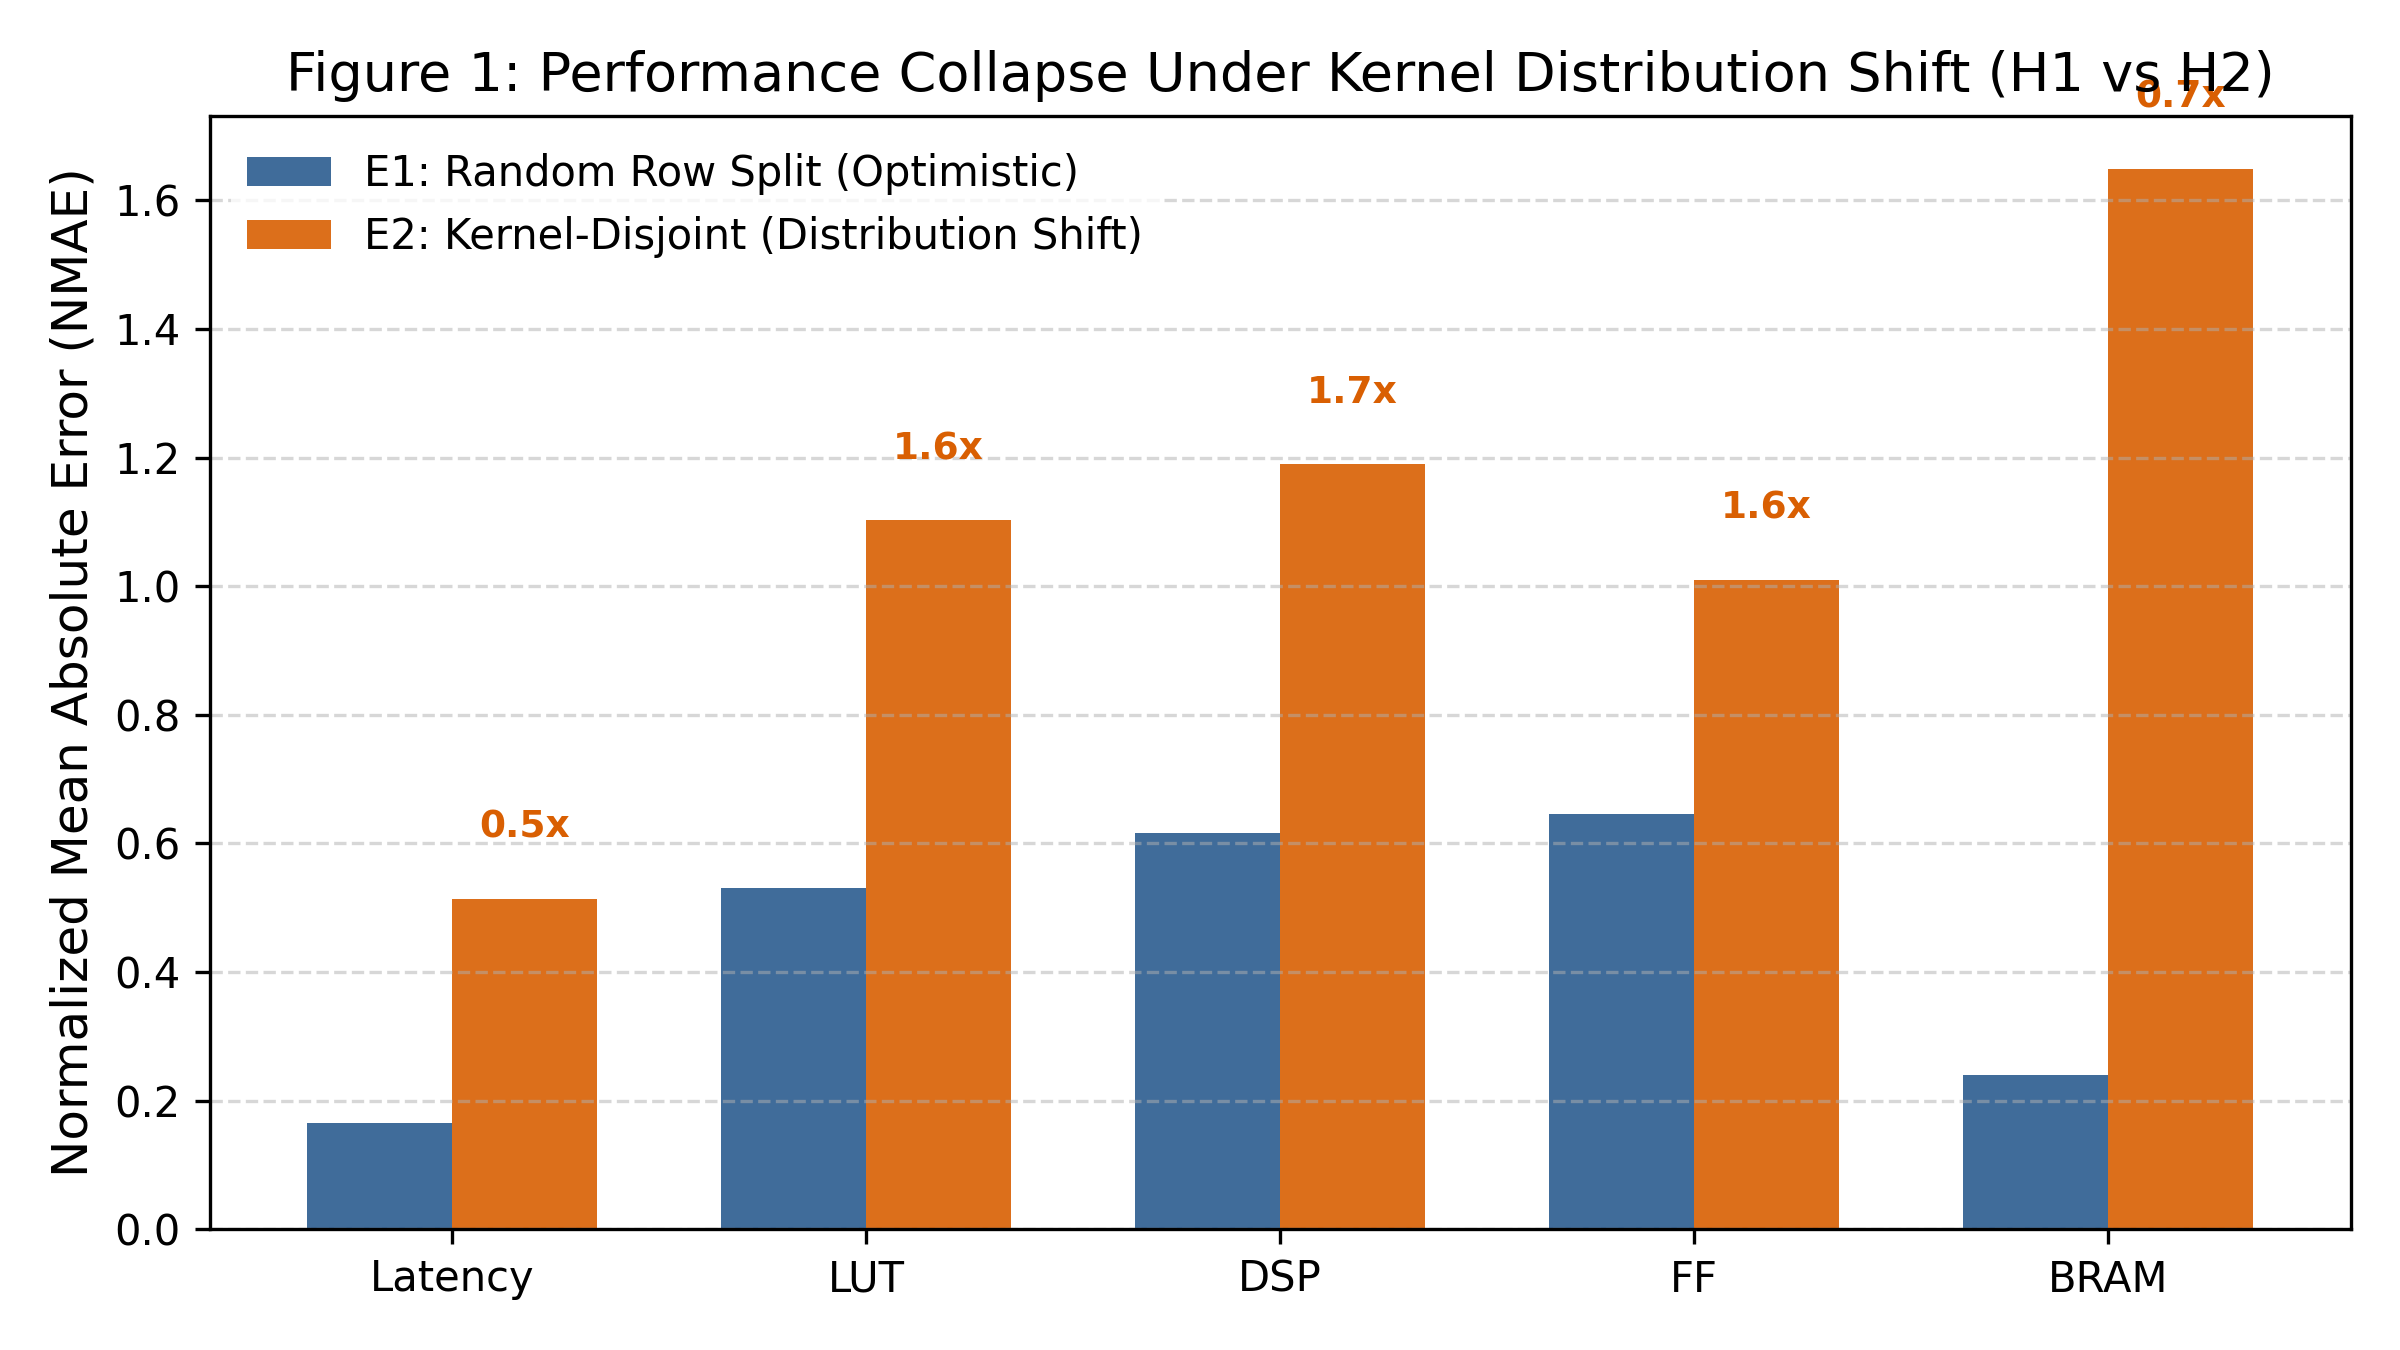

fig2_uncertainty_correlation_quintiles.png OK


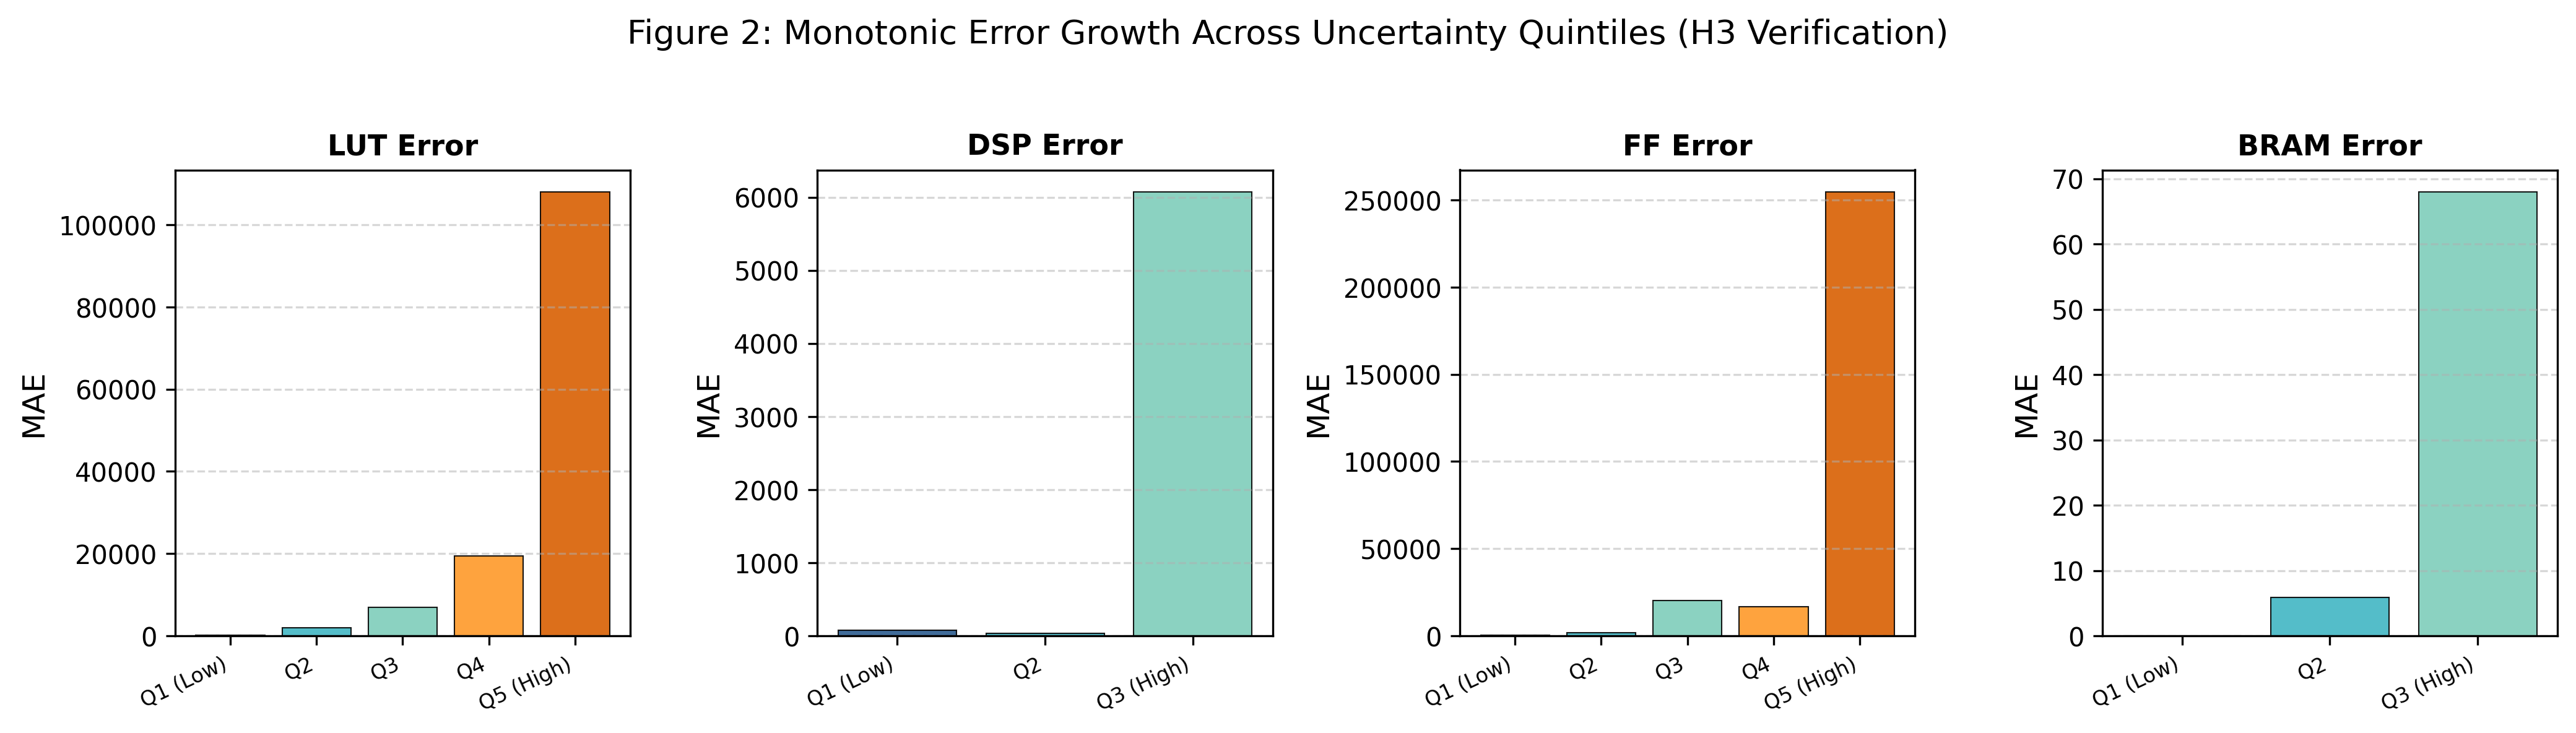

fig3_risk_coverage_curves.png OK


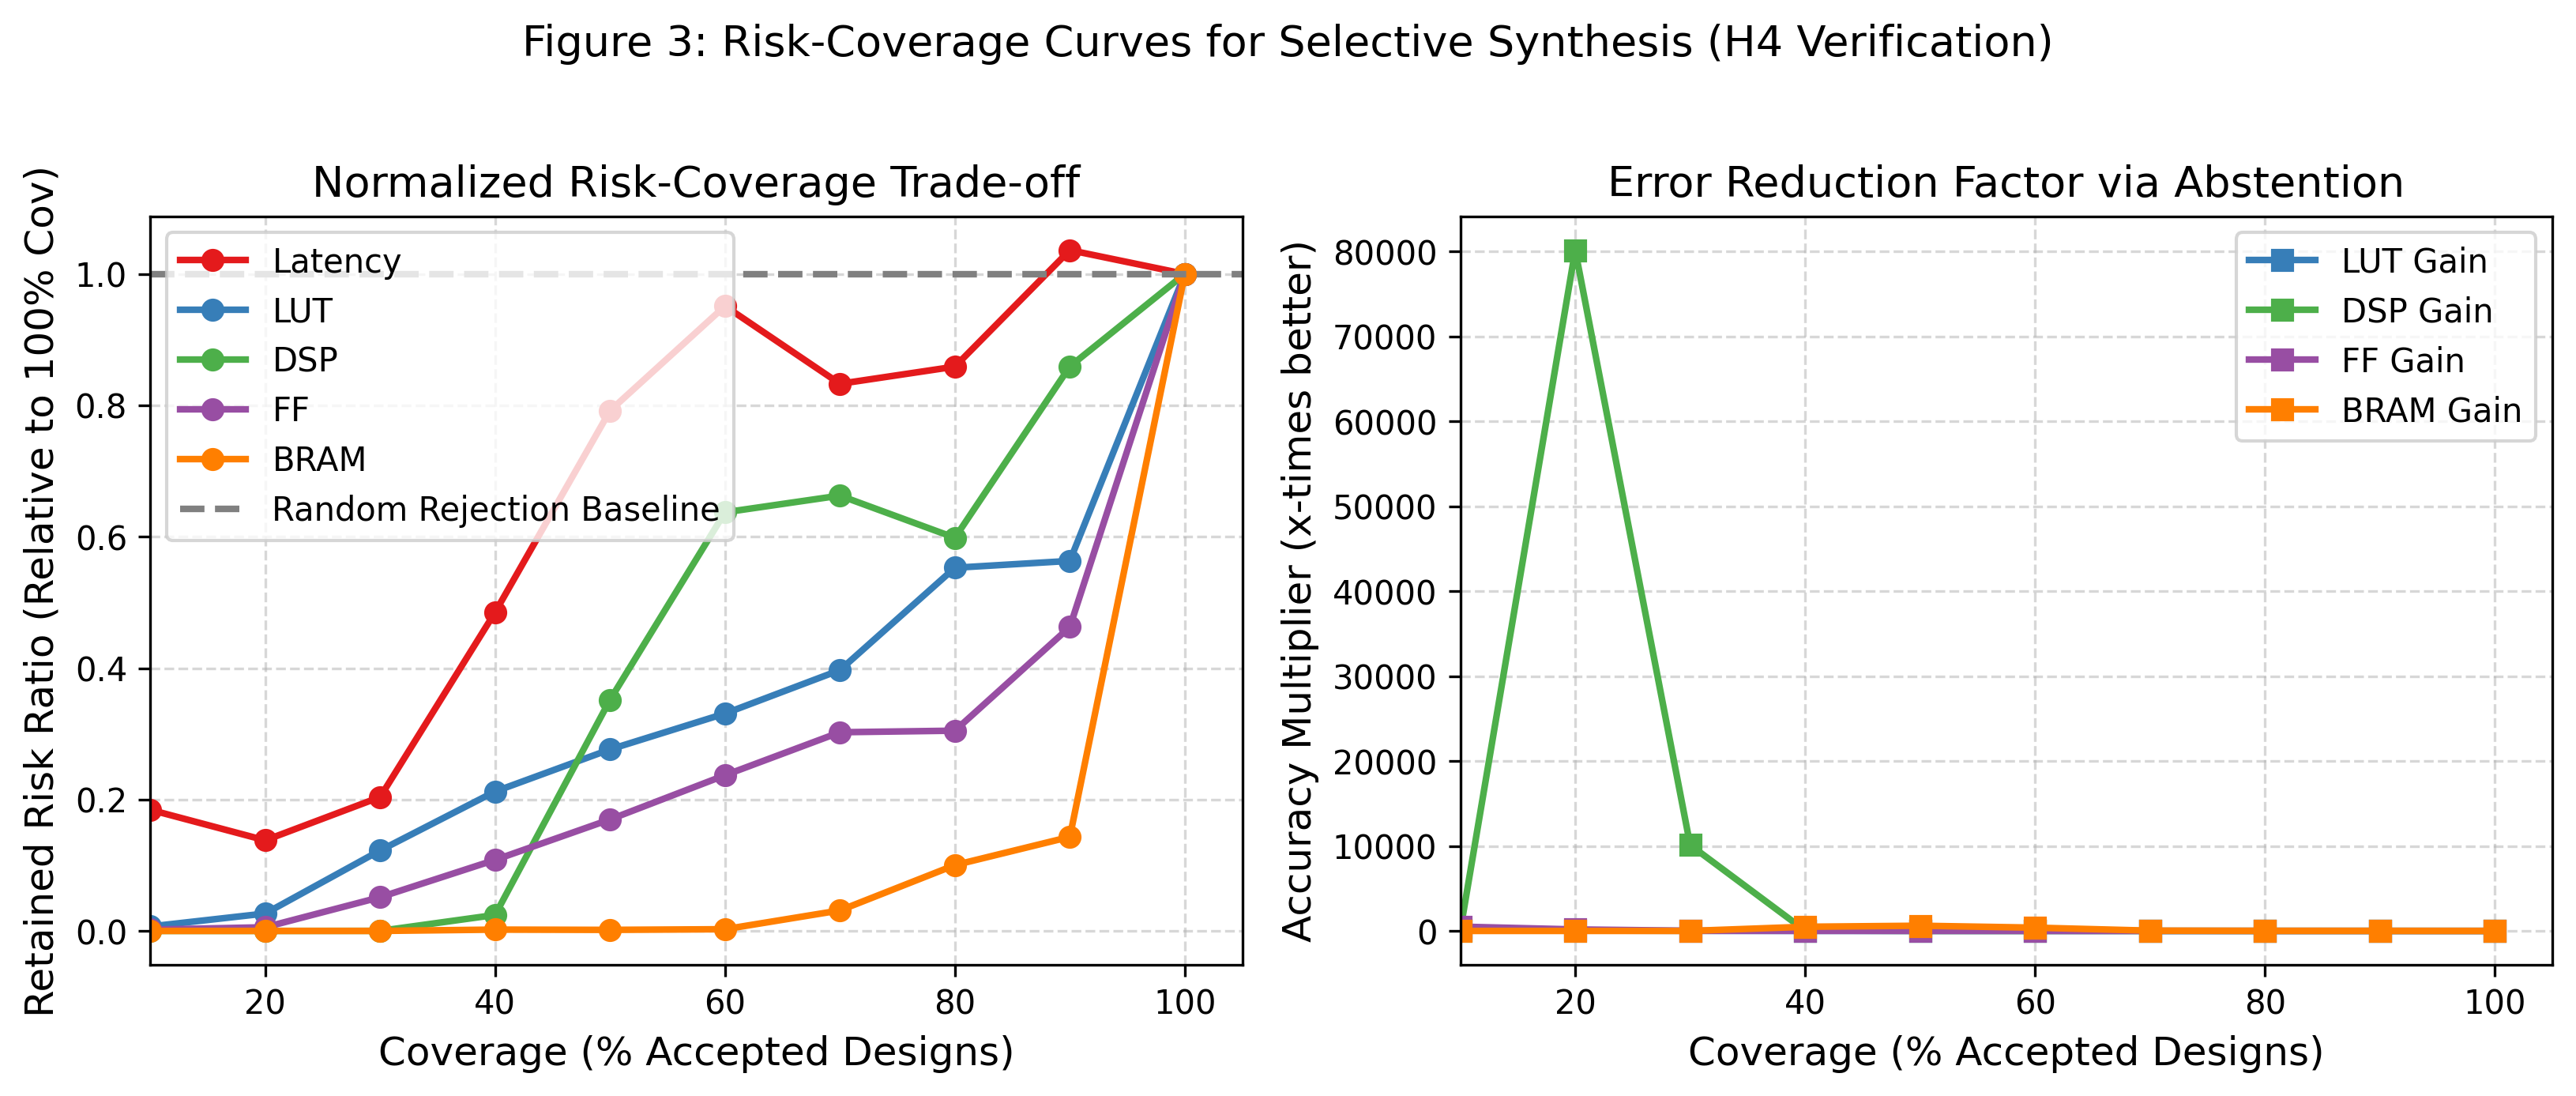

fig4_feature_ablation.png OK


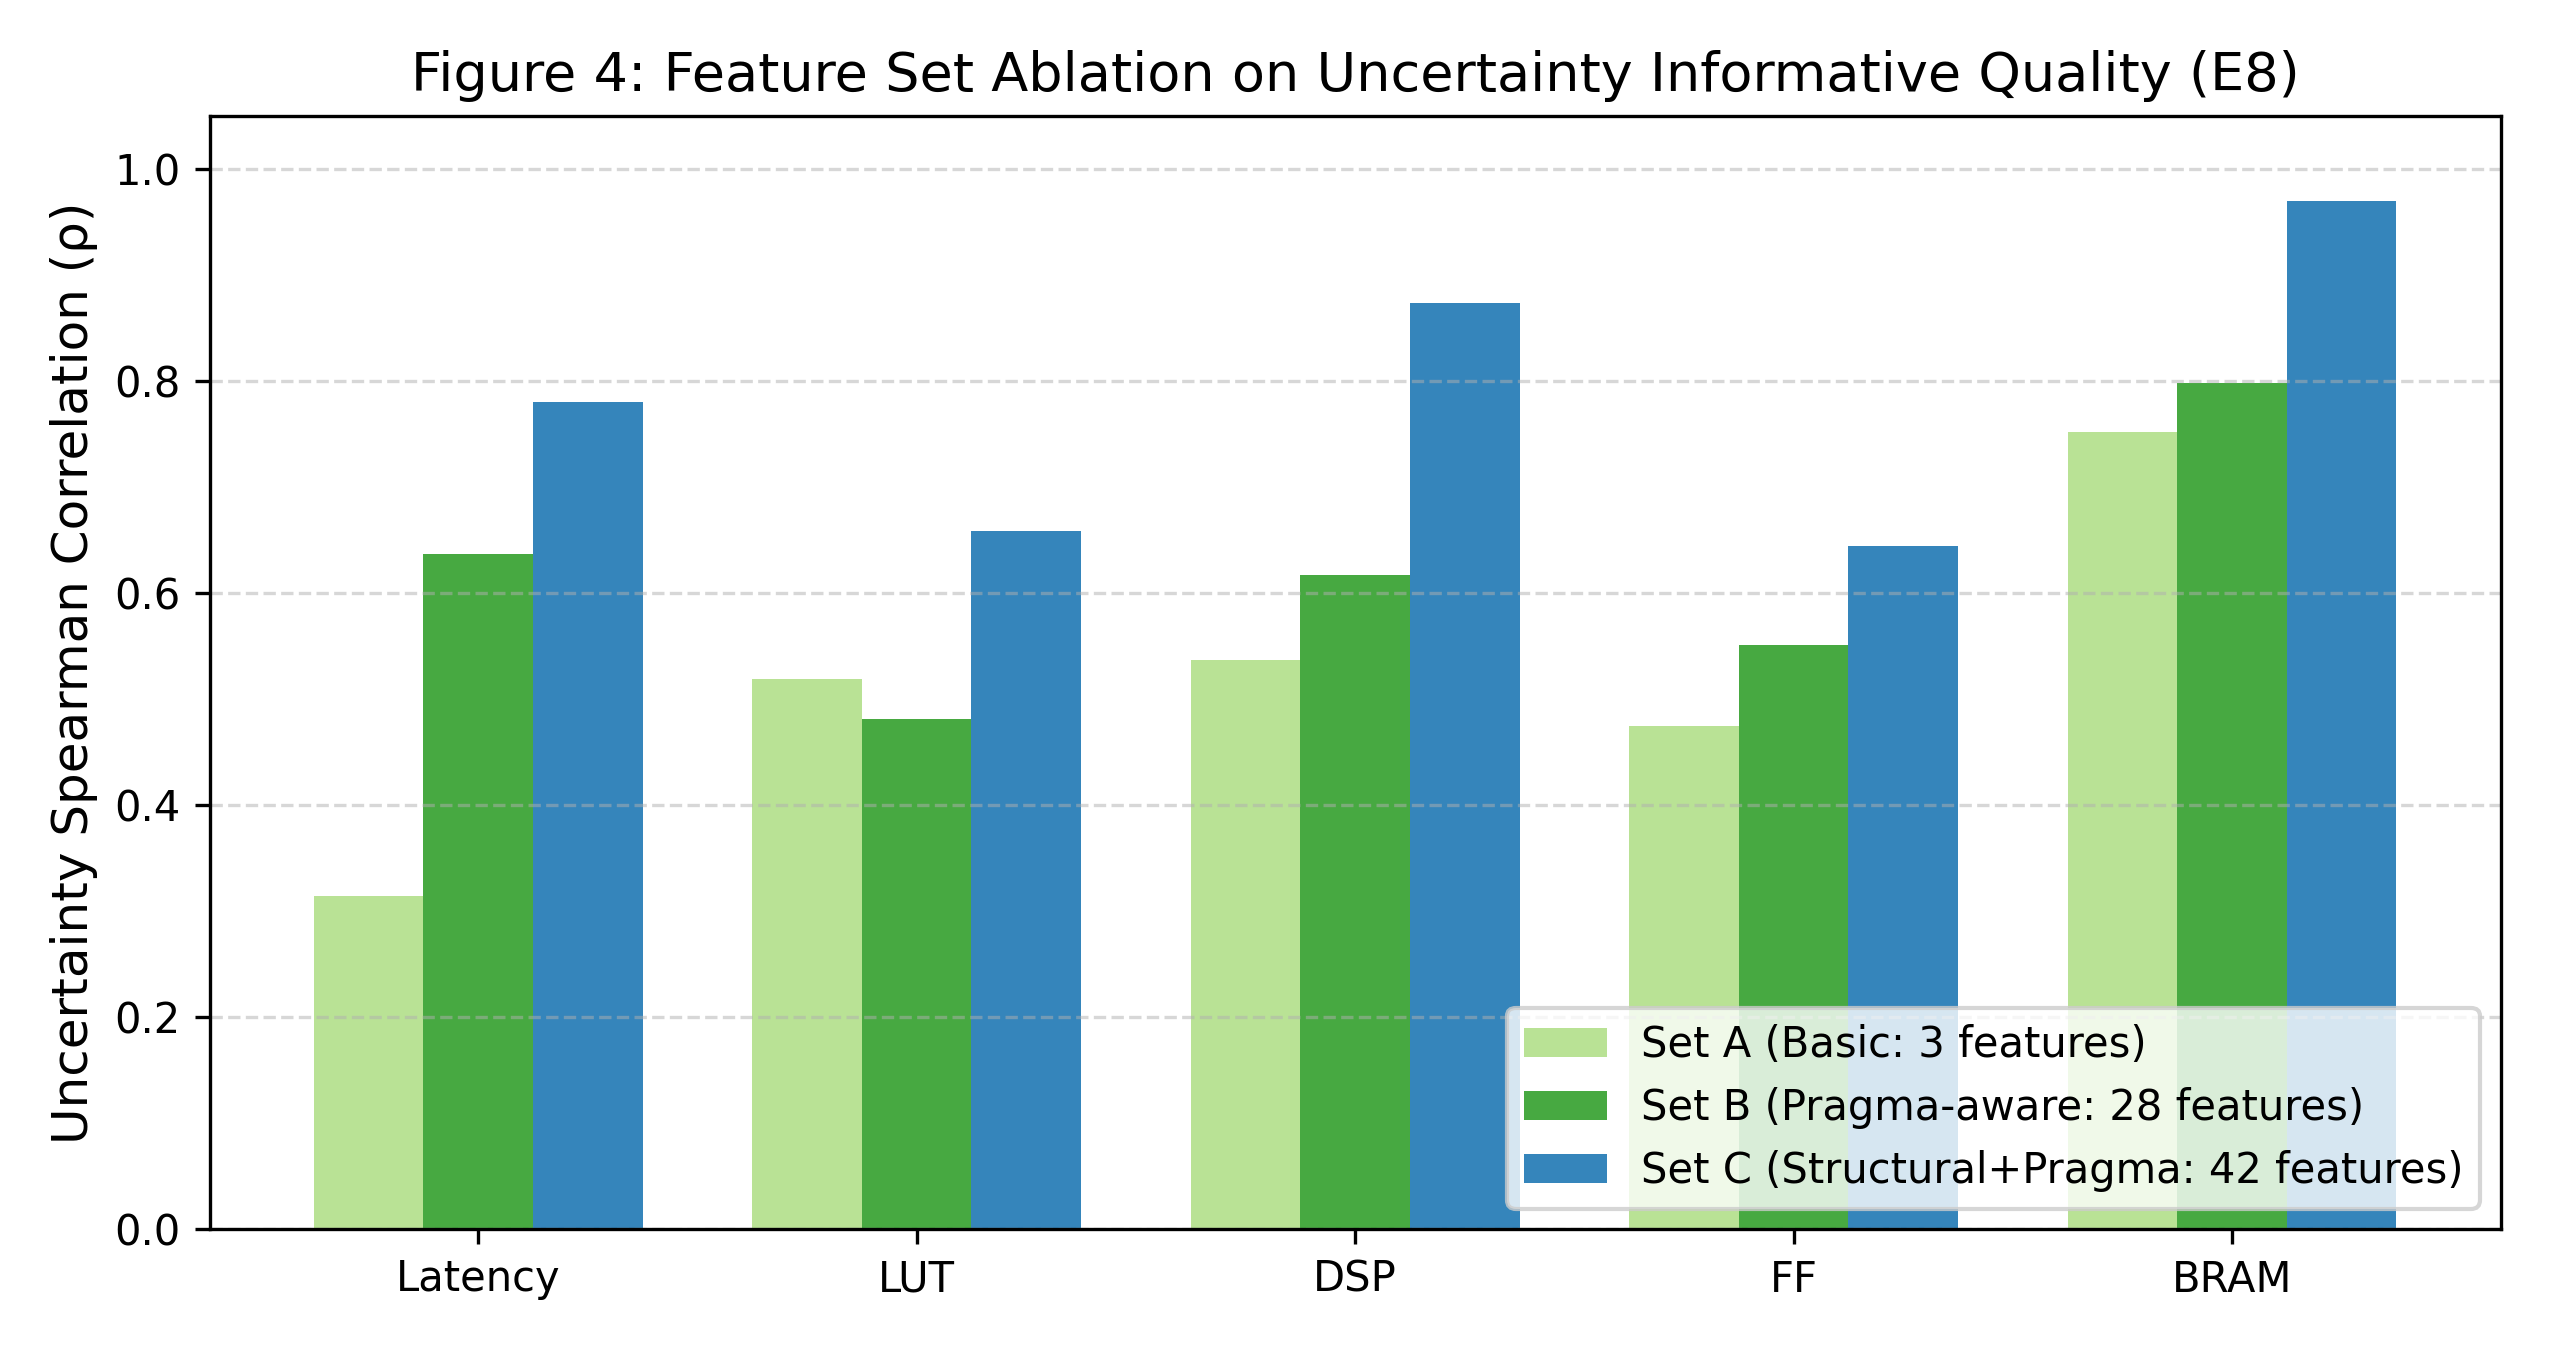

In [29]:
from IPython.display import Image, display
from pathlib import Path

figure_names = [
    "fig1_distribution_shift_e1_vs_e2.png",
    "fig2_uncertainty_correlation_quintiles.png",
    "fig3_risk_coverage_curves.png",
    "fig4_feature_ablation.png",
]

for name in figure_names:
    path = Path("figures") / name
    print(name, "OK" if path.exists() else "MISSING")
    assert path.exists()
    display(Image(filename=str(path)))

In [30]:
import os
import pandas as pd

os.makedirs("tables", exist_ok=True)

files = {
    "baseline": "results/baseline_results_e1_vs_e2.csv",
    "repeated": "results/baseline_results_e3_repeated.csv",
    "uncertainty": "results/uncertainty_results.csv",
    "calibration": "results/calibration_metrics.csv",
    "risk_coverage": "results/risk_coverage_data.csv",
    "ablation": "results/feature_ablation_results.csv",
    "tuned_e2": "results/tuned_results_e2.csv",
    "tuned_e3_summary": "results/tuned_results_e3_summary.csv",
}

for name, path in files.items():
    df = pd.read_csv(path)

    df.to_csv(f"tables/{name}.csv", index=False)

    with open(f"tables/{name}.tex", "w", encoding="utf-8") as output:
        output.write(
            df.to_latex(
                index=False,
                float_format="%.4f"
            )
        )

    print("Exported:", name)

print("All tables exported.")

Exported: baseline
Exported: repeated
Exported: uncertainty
Exported: calibration
Exported: risk_coverage
Exported: ablation
Exported: tuned_e2
Exported: tuned_e3_summary
All tables exported.


In [31]:
from pathlib import Path
import pandas as pd

print("=== BASELINE SUMMARY ===")
print(Path("results/baseline_summary.txt").read_text())

print("\n=== UNCERTAINTY SUMMARY ===")
print(Path("results/uncertainty_summary.txt").read_text())

print("\n=== CALIBRATION SUMMARY ===")
print(Path("results/calibration_selective_summary.txt").read_text())

print("\n=== RESULT FILES ===")
for path in sorted(Path("results").glob("*")):
    print(path, round(path.stat().st_size / 1024, 1), "KB")

=== BASELINE SUMMARY ===
Baseline QoR Prediction & Distribution Shift Summary (E1, E2, E3)

1. Hypothesis H1 & H2 Verification (Random vs Kernel-Disjoint):
---------------------------------------------------------------------------
  * Ridge           : raw E1 R² = -0.089 --> raw E2 R² = -1774.522 | raw MAE ratio = 25.30x | log-MAE E1/E2 = 1.0596/1.3837
  * RandomForest    : raw E1 R² = 0.495 --> raw E2 R² = 0.075 | raw MAE ratio = 1.22x | log-MAE E1/E2 = 0.2608/1.0090
  * GradientBoosting: raw E1 R² = 0.369 --> raw E2 R² = 0.174 | raw MAE ratio = 0.90x | log-MAE E1/E2 = 0.3285/0.9380
  * MLP             : raw E1 R² = 0.374 --> raw E2 R² = -1018.906 | raw MAE ratio = 19.22x | log-MAE E1/E2 = 0.3852/1.3877

  [VERIFICATION]:
  - H1 SUPPORTED: the measured random-vs-grouped comparison is reported above.
  - H2 SUPPORTED: based on log-MAE; raw-scale MAE is reported but not used as the primary test.

2. E3 (Repeated Grouped 5 Seeds Stability - RandomForest):
-------------------------------

In [32]:
from pathlib import Path
import shutil

DRIVE_HLS = Path("/content/drive/MyDrive/VLSI CODE/ForgeHLS/hls_ml")

for folder in ["data", "results", "figures", "tables"]:
    source = Path(folder)
    destination = DRIVE_HLS / folder
    destination.mkdir(parents=True, exist_ok=True)

    for item in source.iterdir():
        target = destination / item.name

        if item.is_file():
            shutil.copy2(item, target)
        elif item.is_dir():
            shutil.copytree(item, target, dirs_exist_ok=True)

    print("Synced:", folder)

print("Fresh data, results, figures, and tables copied to Google Drive.")

Synced: data
Synced: results
Synced: figures
Synced: tables
Fresh data, results, figures, and tables copied to Google Drive.


In [33]:
from pathlib import Path
from datetime import datetime

for folder in ["results", "figures", "tables"]:
    print(f"\n--- {folder} ---")

    for path in sorted(Path(folder).glob("*")):
        modified = datetime.fromtimestamp(path.stat().st_mtime)
        print(modified.strftime("%Y-%m-%d %H:%M:%S"), path.name)


--- results ---
2026-10-27 15:54:30 ablation_summary.txt
2026-10-27 15:08:11 baseline_e2_predictions.npz
2026-10-27 15:08:11 baseline_results_e1_vs_e2.csv
2026-10-27 15:21:25 baseline_results_e3_repeated.csv
2026-10-27 15:21:25 baseline_summary.txt
2026-10-27 15:58:45 calibration_metrics.csv
2026-10-27 15:58:45 calibration_selective_summary.txt
2026-10-27 14:40:48 dataset_audit_summary.txt
2026-10-27 15:54:30 feature_ablation_results.csv
2026-10-27 14:39:55 kernel_group_audit.csv
2026-10-27 14:39:55 pragma_audit_summary.txt
2026-10-27 14:39:55 pragma_frequency.csv
2026-10-27 15:58:45 risk_coverage_data.csv
2026-10-27 14:39:55 source_normalization_audit.csv
2026-10-27 14:48:17 splits_summary.txt
2026-10-27 15:37:10 tuned_model_selection.csv
2026-10-27 15:37:10 tuned_results_e2.csv
2026-10-27 15:52:10 tuned_results_e3_by_seed.csv
2026-10-27 15:52:10 tuned_results_e3_summary.csv
2026-10-27 15:58:43 uncertainty_predictions.npz
2026-10-27 15:58:42 uncertainty_results.csv
2026-10-27 15:58:4